# Notebook 6 — RF and synchrotron radiation

Install an RF cavity in one of the saved rings, enable mean synchrotron radiation, and inspect the closed-orbit momentum deviation $\delta=(p-p_0)/p_0$ along the ring. For these ultrarelativistic electrons, this also describes the relative energy variation to a very good approximation.

## Your tasks

1. Load `ring_dba.json` or `ring_fodo.json` and estimate the energy loss per turn from radiation integrals.
2. Install a **1 MV** cavity halfway around the ring. Use harmonic number **400**, so the RF frequency is an integer multiple of the revolution frequency.
3. Calculate the 6D optics without radiation, then enable mean radiation and recalculate the periodic orbit and optics.
4. Plot $\delta$ versus $s$ over the full ring and around the cavity. Identify where particles lose and regain energy.
5. Repeat for the other ring. Compare the sawtooth amplitudes with the radiation-integral energy losses.

We use the [Xsuite mean-radiation model](https://xsuite.readthedocs.io/en/latest/synchrotron_radiation.html): deterministic energy loss without random photon emission. The 6D closed-orbit calculation finds the synchronous arrival time at the cavity.

### Load a matched ring

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from scipy.constants import c
import xtrack as xt

In [2]:
lattice_file = 'ring_dba.json'  # Or 'ring_fodo.json'
line = xt.load(lattice_file)

Loading line from dict:   0%|          | 0/209 [00:00<?, ?it/s]

Done loading line from dict.           


### Sample the bends and estimate the energy loss

Use thick slices to resolve the momentum change inside the magnets.

In [3]:
line.slice_thick_elements(slicing_strategies=[
    xt.Strategy(slicing=None),
    xt.Strategy(slicing=xt.Uniform(100, mode='thick'), element_type=xt.Bend),
    xt.Strategy(slicing=xt.Uniform(2, mode='thick'), element_type=xt.Quadrupole),
    xt.Strategy(slicing=xt.Uniform(2, mode='thick'), element_type=xt.Sextupole),
])
tw_integrals = line.twiss4d(radiation_integrals=True)
print(f'Energy loss from radiation integrals: {tw_integrals.rad_int_energy_loss / 1e3:.3f} keV/turn')

Slicing line:   0%|          | 0/384 [00:00<?, ?it/s]

Energy loss from radiation integrals: 170.674 keV/turn


### Install the cavity

Set $f_{\mathrm{RF}}=h\beta_0 c/C$. The chosen voltage exceeds the energy loss per turn for both rings. With the Xsuite phase convention used here, `phase=np.pi` gives the stable zero-gain synchronous phase without radiation for these lattices. When radiation is enabled, the synchronous arrival time shifts so that the cavity restores the lost energy.

In [4]:
harmonic_number = 400
rf_voltage = 1e6  # [V]
f_rev = line.particle_ref.beta0[0] * c / line.get_length()
f_rf = harmonic_number * f_rev
s_rf = line.get_length() / 2

line.insert('rf', xt.Cavity(voltage=rf_voltage, frequency=f_rf, phase=np.pi),
            at=s_rf)
print(f'RF frequency: {f_rf / 1e6:.3f} MHz')

Slicing line:   0%|          | 0/4400 [00:00<?, ?it/s]

RF frequency: 499.654 MHz


### 6D optics without radiation

In [5]:
tw_no_rad = line.twiss(method='6d')
print(f'Synchrotron tune without radiation: {tw_no_rad.qs:.5f}')

Synchrotron tune without radiation: 0.00522


### Enable mean radiation and find the periodic solution

In [6]:
line.configure_radiation(model='mean')
tw_rad = line.twiss(method='6d', radiation_analysis=True)
print(f'Energy loss with radiation: {tw_rad.energy_loss / 1e3:.3f} keV/turn')
print(f'Synchrotron tune with radiation: {tw_rad.qs:.5f}')

Energy loss with radiation: 170.674 keV/turn
Synchrotron tune with radiation: 0.00518


### Momentum sawtooth around the ring

The periodic solution loses momentum in the bends and gains it at the cavity. The momentum at the end of a turn returns to its initial value. Compare the radiating orbit with the constant-momentum orbit without radiation.

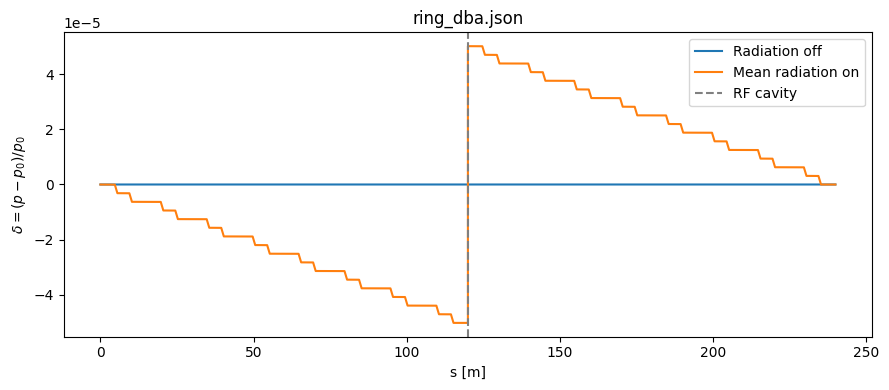

In [7]:
plt.figure(figsize=(9, 4))
plt.plot(tw_no_rad.s, tw_no_rad.delta, label='Radiation off')
plt.plot(tw_rad.s, tw_rad.delta, label='Mean radiation on')
plt.axvline(s_rf, color='grey', linestyle='--', label='RF cavity')
plt.xlabel('s [m]')
plt.ylabel(r'$\delta = (p-p_0)/p_0$')
plt.title(lattice_file)
plt.legend()
plt.tight_layout()

### Zoom around the RF cavity

Use the lattice overlay to identify the losses in the dipoles and the recovery at the cavity.

(104.99999999999731, 134.99999999999733)

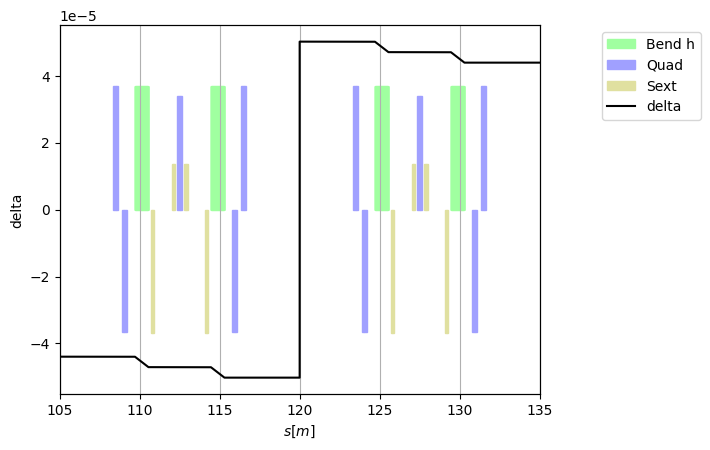

In [8]:
tw_rad.plot('delta')
plt.xlim(s_rf - line['l_cell'], s_rf + line['l_cell'])